# Unit 04 — Population vs. GDP per Capita
**Task A:** Correlation between mean population and mean GDP per capita (2001–2021)
**Task B:** Linear regression of GDP per capita on population

Run the cells top to bottom in Google Colab. When prompted, upload
`Unit04_Global_Population.csv` and `Unit04_Global_GDP.csv`.

In [1]:
# --- Upload the two data files ---
from google.colab import files
uploaded = files.upload()   # select Unit04_Global_Population.csv and Unit04_Global_GDP.csv

Saving Unit04 Global_Population.csv to Unit04 Global_Population.csv
Saving Unit04 Global_GDP.csv to Unit04 Global_GDP.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

pop = pd.read_csv('Unit04 Global_Population.csv')
gdp = pd.read_csv('Unit04 Global_GDP.csv')

pop.head()

,Country Name,Country Code,Series Name,Series Code,1960,1961,1962,1963,1964,1965,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54211,55438,56225,56695,57032,57360,...,102560,103159,103774,104341,104872,105366,105845,106314,NaN,NaN
1,Afghanistan,AFG,"Population, total",SP.POP.TOTL,8996967,9169406,9351442,9543200,9744772,9956318,...,31161378,32269592,33370804,34413603,35383028,36296111,37171922,38041757,38928341,39835000
2,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130836765,134159786,137614644,141202036,144920186,148769974,...,547482863,562601578,578075373,593871847,609978946,626392880,643090131,660046272,677243299,694664000
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,96396419,98407221,100506960,102691339,104953470,107289875,...,370243017,380437896,390882979,401586651,412551299,423769930,435229381,446911598,458803476,470898000
4,Albania,ALB,"Population, total",SP.POP.TOTL,1608800,1659800,1711319,1762621,1814135,1864791,...,2900401,2895092,2889104,2880703,2876101,2873457,2866376,2854191,2837743,2832000


## Task A — Pre-processing

The raw World Bank extracts contain a few things that need cleaning before we
can work with them:

- A handful of footer rows with no `Country Code` (source/notes text) — dropped.
- One duplicated country row (Aruba) — we keep the most recent version.
- The population file runs 2001–2021, the GDP file only runs 2001–2020, so we
  use the **overlapping years 2001–2020** for both series.
- Missing values within that period are ignored when averaging (`skipna=True`),
  rather than treated as zero, so a country with a couple of missing years
  still gets a genuine mean rather than a downward-biased one.

For each country we then compute:
- **mean population** (2001–2020)
- **GDP per capita** for each year = GDP (current US$) / population, then
  **mean GDP per capita** (2001–2020)

In [4]:
# Drop footer rows (no Country Code) and duplicate country rows
pop = pop.dropna(subset=['Country Code']).drop_duplicates(subset='Country Code', keep='last')
gdp = gdp.dropna(subset=['Country Code']).drop_duplicates(subset='Country Code', keep='last')

# Years common to both datasets
years = [str(y) for y in range(2001, 2021)]  # 2001-2020 (GDP file stops at 2020)

pop_y = pop.set_index('Country Code')[years].apply(pd.to_numeric, errors='coerce')
gdp_y = gdp.set_index('Country Code')[years].apply(pd.to_numeric, errors='coerce')

# Keep countries/entities present in both files
common = pop_y.index.intersection(gdp_y.index)
pop_y, gdp_y = pop_y.loc[common], gdp_y.loc[common]

# GDP per capita, year by year, then the two country-level means
gdp_percap_y = gdp_y / pop_y
mean_population = pop_y.mean(axis=1, skipna=True)
mean_gdp_percapita = gdp_percap_y.mean(axis=1, skipna=True)

names = pop.set_index('Country Code')['Country Name']
data = pd.DataFrame({
    'Country Name': names.loc[common],
    'mean_population': mean_population,
    'mean_gdp_percapita': mean_gdp_percapita
}).dropna()   # drop countries with no usable data in either series

print(f'{data.shape[0]} countries/entities with complete data')
data.sort_values('mean_gdp_percapita', ascending=False).head(10)

256 countries/entities with complete data


,Country Name,mean_population,mean_gdp_percapita
Country Code,,,
MCO,Monaco,35897.45,152610.101196
LIE,Liechtenstein,36110.75,138115.293315
LUX,Luxembourg,523287.55,100267.387806
BMU,Bermuda,64348.95,94780.323307
CYM,Cayman Islands,56101.50,79772.726331
NOR,Norway,4930794.15,76396.703438
CHE,Switzerland,7897657.35,72862.615632
IMN,Isle of Man,82593.90,63666.919454
QAT,Qatar,1810642.70,60627.241658


> **Note:** this World Bank extract mixes individual countries with regional/
> income-group aggregates (e.g. *World*, *High income*, *Sub-Saharan Africa*).
> The code above treats every row the same way. If your seminar group wants a
> country-only analysis, filter `data` to a list of real ISO-3 country codes
> before Task A/B — worth raising as a discussion point.

## Task A — Scatter plot & Pearson correlation

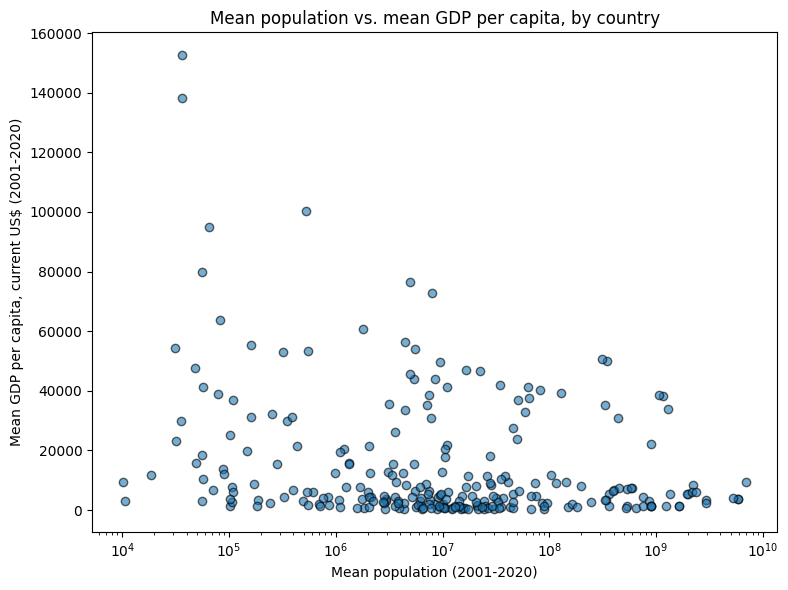

Pearson correlation coefficient r = -0.099
p-value = 0.1142


In [5]:
plt.figure(figsize=(8,6))
plt.scatter(data['mean_population'], data['mean_gdp_percapita'], alpha=0.6, edgecolor='k')
plt.xlabel('Mean population (2001-2020)')
plt.ylabel('Mean GDP per capita, current US$ (2001-2020)')
plt.title('Mean population vs. mean GDP per capita, by country')
plt.xscale('log')  # population is heavily skewed - log scale makes the pattern visible
plt.tight_layout()
plt.show()

r, p_value = stats.pearsonr(data['mean_population'], data['mean_gdp_percapita'])
print(f'Pearson correlation coefficient r = {r:.3f}')
print(f'p-value = {p_value:.4f}')

**Interpretation:** the Pearson correlation coefficient is close to zero and
slightly negative (r ≈ -0.10, not statistically significant at p ≈ 0.11). In
other words, across countries there is essentially **no linear relationship**
between how large a country's population is and how rich its citizens are on
average. The scatter plot (population on a log scale, because a few very
large countries would otherwise dominate the picture) shows points scattered
across the full range of GDP per capita at every population size — small
countries (e.g. Monaco, Luxembourg) can be extremely rich or extremely poor,
and the same is true for large countries (e.g. USA vs. India). Population
size on its own is a poor predictor of prosperity; other factors (natural
resources, institutions, trade, industrialisation) matter far more.

## Task B — Linear regression

In [ ]:
X = data[['mean_population']].values          # independent variable
y = data['mean_gdp_percapita'].values          # dependent variable

model = LinearRegression().fit(X, y)
y_pred = model.predict(X)

slope = model.coef_[0]
intercept = model.intercept_
r2 = r2_score(y, y_pred)

print(f'Regression equation:  GDP per capita = {intercept:,.2f} + ({slope:.6f}) * population')
print(f'R-squared = {r2:.4f}')

plt.figure(figsize=(8,6))
plt.scatter(data['mean_population'], data['mean_gdp_percapita'], alpha=0.6, edgecolor='k', label='Countries')
order = data['mean_population'].argsort()
plt.plot(data['mean_population'].values[order], y_pred[order], color='red', linewidth=2, label='Regression line')
plt.xlabel('Mean population (2001-2020)')
plt.ylabel('Mean GDP per capita, current US$ (2001-2020)')
plt.title('Linear regression: GDP per capita on population')
plt.xscale('log')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** the fitted line is essentially flat — the slope is a
tiny negative number and **R² ≈ 0.01**, meaning population explains
about 1% of the variation in GDP per capita across countries. This confirms
the Task A finding: a simple linear model using population alone is not a
useful predictor of GDP per capita. This is expected — GDP per capita is
driven by productivity, institutions, capital, and trade, not by raw
population size, and it's a good discussion point for the seminar: what
other variables might explain the variation better?